# Stage 2 – Cleaning

**Input:** `data/interim/lc_36m_2009_2015.parquet`, the 36-month loans issued 2009-2015 saved by stage 1.

**Output:** `data/processed/loans_clean.parquet`, one row per loan with the target, the issue quarter and only the information that was known when the borrower applied.

Every rule that removes rows is counted, so the final table can go straight into the Data section of the paper.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from helpers import (DEV_YEARS, FEATURES, FIGURES, INK, INK_SOFT, INTERIM, MODEL_COLORS, PROCESSED, SEED,
                     label_quarters, set_plot_style)

set_plot_style()

loans = pd.read_parquet(INTERIM / "lc_36m_2009_2015.parquet")
row_counts = pd.read_csv(INTERIM / "row_counts.csv", index_col="step")["rows"].to_dict()
print(f"{len(loans):,} loans, {loans.shape[1]} columns")

618,173 loans, 34 columns


## 1. Target

A loan is bad (1) when it was charged off or defaulted and good (0) when it was fully paid. The older loans marked "Does not meet the credit policy" are kept with the same rule. Loans that are still running (Current, Late, In Grace Period) have no final outcome yet, so they are removed.

In [2]:
BAD = ["Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"]
GOOD = ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]
status_to_target = {status: 1 for status in BAD} | {status: 0 for status in GOOD}

loans["target"] = loans["loan_status"].map(status_to_target)
print("Removed because the outcome is not final:")
print(loans.loc[loans["target"].isna(), "loan_status"].value_counts().to_string())

loans = loans[loans["target"].notna()].copy()
loans["target"] = loans["target"].astype(int)
row_counts["With a final outcome"] = len(loans)

Removed because the outcome is not final:
loan_status
Current               72
Late (31-120 days)    61
In Grace Period        9
Late (16-30 days)      5


## 2. Cohort

The cohort of a loan is the quarter in which it was issued. All the monitoring in the next stages is done cohort by cohort.

In [3]:
loans["issue_year"] = loans["issue_d"].dt.year
loans["issue_quarter"] = loans["issue_d"].dt.to_period("Q").astype(str)

cohorts_full = loans.groupby("issue_quarter")["target"].agg(loans_full="size", default_rate_full="mean")
loans.groupby("issue_year")["target"].agg(loans="size", default_rate="mean").round(4)

,loans,default_rate
issue_year,,
2009,5281,0.1369
2010,9156,0.1092
2011,14101,0.1063
2012,43470,0.1358
2013,100422,0.1233
2014,162570,0.1373
2015,283026,0.1489


## 3. Lender variables and leakage

Two kinds of columns must stay out of the models:

- **Post-origination columns** (payments received, recoveries, last FICO score, hardship and settlement plans). They are created after the loan is issued, so they already contain the outcome. Stage 1 never loads them; the check below makes sure none slipped in.
- **Lender variables** (`grade`, `sub_grade`, and the interest rate that follows from them). They are the output of Lending Club's own model. They are kept apart as a benchmark, a third model "in production", and are never used as features.

In [4]:
LEAKAGE_PREFIXES = ("total_pymnt", "total_rec_", "last_pymnt_", "recoveries", "collection_recovery",
                    "out_prncp", "last_fico_", "next_pymnt_d", "last_credit_pull_d", "hardship",
                    "settlement", "debt_settlement")
leaking = [column for column in loans.columns if column.startswith(LEAKAGE_PREFIXES)]
assert not leaking, f"Post-origination columns found: {leaking}"

BENCHMARK = ["grade", "sub_grade"]
print("Share of each Lending Club grade by issue year (%):")
(pd.crosstab(loans["grade"], loans["issue_year"], normalize="columns") * 100).round(1)

Share of each Lending Club grade by issue year (%):


issue_year,2009,2010,2011,2012,2013,2014,2015
grade,,,,,,,
A,22.8,28.0,39.6,24.7,17.0,21.7,24.8
B,27.4,30.6,33.5,38.7,40.1,32.9,32.4
C,25.5,22.6,15.6,22.8,24.6,27.1,27.4
D,15.5,13.7,8.9,11.7,14.4,12.6,11.6
E,5.8,3.7,1.9,1.8,3.2,4.3,3.3
F,2.0,1.0,0.4,0.2,0.6,1.2,0.5
G,1.0,0.4,0.1,0.1,0.0,0.1,0.1


## 4. Missing values by year

A feature is useful only if it already existed in the development years (2009-2011). The table shows the share of missing values per issue year; columns that are missing for more than half of the loans in any development year are dropped.

In [5]:
not_features = ["id", "issue_d", "term", "loan_status", "target", "issue_year", "issue_quarter"] + BENCHMARK
candidates = [column for column in loans.columns if column not in not_features]

missing_by_year = loans[candidates].isna().groupby(loans["issue_year"]).mean().T * 100
too_empty = missing_by_year.index[(missing_by_year[DEV_YEARS] > 50).any(axis=1)].tolist()
print("Dropped:", too_empty)
loans = loans.drop(columns=too_empty)

missing_by_year.round(1)

Dropped: ['mths_since_last_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_util', 'mort_acc', 'mths_since_recent_inq', 'percent_bc_gt_75']


issue_year,2009,2010,2011,2012,2013,2014,2015
loan_amnt,0.0,0.0,0.0,0.0,0.0,0.0,0.0
emp_title,5.6,6.6,7.2,6.4,7.1,6.5,6.7
emp_length,0.0,3.1,3.9,4.0,5.0,5.9,6.7
home_ownership,0.0,0.0,0.0,0.0,0.0,0.0,0.0
annual_inc,0.0,0.0,0.0,0.0,0.0,0.0,0.0
verification_status,0.0,0.0,0.0,0.0,0.0,0.0,0.0
purpose,0.0,0.0,0.0,0.0,0.0,0.0,0.0
dti,0.0,0.0,0.0,0.0,0.0,0.0,0.0
delinq_2yrs,0.0,0.0,0.0,0.0,0.0,0.0,0.0
earliest_cr_line,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Features

The raw columns are turned into the model features:

- `credit_history_years`: years between the first credit line and the issue date.
- `fico`: middle of the FICO range at origination.
- `emp_length_years`: "< 1 year" becomes 0 and "10+ years" becomes 10; a missing answer stays missing and is handled inside the models (median plus a "missing" flag).
- Income and revolving balance are very skewed, so their logarithm is used.
- Only impossible values are corrected: a DTI above 40 (Lending Club's own maximum) and a revolving utilisation above 100%.
- The three rarest home ownership answers are merged into `OTHER`.

In [6]:
first_credit_line = pd.to_datetime(loans["earliest_cr_line"], format="%b-%Y")
loans["credit_history_years"] = (loans["issue_d"] - first_credit_line).dt.days / 365.25

loans["fico"] = (loans["fico_range_low"] + loans["fico_range_high"]) / 2

loans["emp_length_years"] = loans["emp_length"].str.extract(r"(\d+)")[0].astype(float)
loans.loc[loans["emp_length"] == "< 1 year", "emp_length_years"] = 0

loans["log_annual_inc"] = np.log1p(loans["annual_inc"])
loans["log_revol_bal"] = np.log1p(loans["revol_bal"])

print("DTI above 40:", (loans["dti"] > 40).sum(), "| utilisation above 100%:", (loans["revol_util"] > 100).sum())
loans["dti"] = loans["dti"].clip(upper=40)
loans["revol_util"] = loans["revol_util"].clip(upper=100)

loans["home_ownership"] = loans["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

loans[FEATURES].describe(include="all").T[["count", "unique", "top", "mean", "min", "50%", "max"]]

DTI above 40: 34 | utilisation above 100%: 2203


,count,unique,top,mean,min,50%,max
loan_amnt,618026.0,NaN,NaN,12499.067596,1000.0,10000.0,35000.0
log_annual_inc,618026.0,NaN,NaN,11.029937,0.0,11.002117,16.012735
dti,618024.0,NaN,NaN,17.569551,0.0,17.04,40.0
fico,618026.0,NaN,NaN,697.067966,662.0,692.0,847.5
emp_length_years,581861.0,NaN,NaN,5.851896,0.0,6.0,10.0
log_revol_bal,618026.0,NaN,NaN,9.176391,0.0,9.272094,14.881888
revol_util,617684.0,NaN,NaN,53.742911,0.0,54.3,100.0
open_acc,618026.0,NaN,NaN,11.256795,0.0,10.0,84.0
total_acc,618026.0,NaN,NaN,24.497612,2.0,23.0,169.0
delinq_2yrs,618026.0,NaN,NaN,0.315068,0.0,0.0,30.0


## 6. Occupation

`emp_title` changed meaning: for loans listed before 23 September 2013 it holds the name of the employer, afterwards the job title. The table shows the switch in the data: the share of titles containing a common job word jumps from under 1% to about 25% with the loans issued in October 2013. The occupation analysis is therefore valid only from the 2013Q4 cohort, marked by the flag `title_is_job`.

In [7]:
title = (loans["emp_title"].fillna("").str.lower()
         .str.replace(r"[^a-z ]", " ", regex=True)
         .str.replace(r"\s+", " ", regex=True).str.strip())

has_job_word = title.str.contains("manager|teacher|nurse|driver|engineer")
issue_month = loans["issue_d"].dt.to_period("M").rename("issue_month")
print("Share of titles with a common job word (%):")
print((has_job_word.groupby(issue_month).mean().loc["2013-07":"2013-12"] * 100).round(1).to_string())

loans["title_is_job"] = loans["issue_d"] >= "2013-10-01"

Share of titles with a common job word (%):
issue_month
2013-07     0.3
2013-08     0.5
2013-09     0.4
2013-10    23.5
2013-11    26.3
2013-12    25.9
Freq: M


The groups are chosen from the data: the table lists the most frequent words in the job titles. The 18 most frequent words that name a job become the groups (generic words such as "senior" or "service" are skipped, and abbreviations are merged with the full word).

In [8]:
words = title[loans["title_is_job"]].str.split().explode()
word_share = words.value_counts() / loans["title_is_job"].sum() * 100
print("Most frequent words (% of titles):")
print(", ".join(f"{word} {share:.1f}" for word, share in word_share.head(40).items()))

Most frequent words (% of titles):
manager 14.6, director 4.0, assistant 3.8, sales 3.6, teacher 3.0, supervisor 2.8, engineer 2.7, specialist 2.7, analyst 2.7, senior 2.6, driver 2.3, nurse 2.2, service 2.1, of 1.9, technician 1.9, officer 1.9, owner 1.8, coordinator 1.6, tech 1.6, sr 1.5, associate 1.5, operations 1.4, operator 1.4, president 1.4, project 1.4, registered 1.3, office 1.3, executive 1.2, rn 1.2, lead 1.2, consultant 1.1, business 1.0, account 1.0, clerk 1.0, administrator 1.0, customer 1.0, it 0.9, general 0.9, support 0.8, vice 0.8


A title can contain two keywords ("sales manager"). The dictionary is ordered so that the first match wins: the specific profession comes before the level in the hierarchy. Everything without a keyword is `Other`, an empty title is `Missing`.

In [9]:
OCCUPATIONS = {
    "teacher": r"teacher",
    "nurse": r"nurse|\brn\b|\blpn\b",
    "driver": r"driver",
    "engineer": r"engineer",
    "technician": r"technician|\btech\b",
    "analyst": r"analyst",
    "sales": r"sales",
    "consultant": r"consultant",
    "officer": r"officer|police",
    "operator": r"operator",
    "owner": r"owner",
    "executive": r"president|\bvp\b|\bceo\b",
    "director": r"director",
    "manager": r"manager|\bmgr\b",
    "supervisor": r"supervisor",
    "coordinator": r"coordinator",
    "specialist": r"specialist",
    "assistant": r"assistant|\basst\b",
}

group = pd.Series("Other", index=loans.index)
# Going backwards lets the groups listed first overwrite the later ones.
for name, pattern in reversed(OCCUPATIONS.items()):
    group[title.str.contains(pattern)] = name
group[title == ""] = "Missing"
loans["occupation_group"] = group

with_job_title = loans[loans["title_is_job"]]
occupation_table = with_job_title.groupby("occupation_group")["target"].agg(loans="size", default_rate="mean")
occupation_table["share_%"] = occupation_table["loans"] / len(with_job_title) * 100
occupation_table.sort_values("loans", ascending=False).round(3)

,loans,default_rate,share_%
occupation_group,,,
Other,173870,0.146,36.407
manager,65666,0.132,13.750
Missing,32104,0.207,6.722
director,17634,0.099,3.692
sales,17249,0.155,3.612
nurse,17029,0.134,3.566
technician,16525,0.157,3.460
engineer,14372,0.089,3.009
assistant,14324,0.141,2.999


## 7. Sample

All the loans issued in 2009-2011 are kept, because they are the development sample. From 2012 the quarters become much larger, so at most 12,000 loans per quarter are drawn at random (seed 42). This keeps every stage light enough to run on Nuvolos.

In [10]:
MAX_PER_QUARTER = 12_000

loans = loans.sort_values("id")
development = loans[loans["issue_year"].isin(DEV_YEARS)]
monitoring = loans[~loans["issue_year"].isin(DEV_YEARS)]

# Shuffle once, then keep the first 12,000 loans of every quarter.
monitoring = monitoring.sample(frac=1, random_state=SEED)
monitoring = monitoring.groupby("issue_quarter").head(MAX_PER_QUARTER)

sample = pd.concat([development, monitoring]).sort_values(["issue_d", "id"]).reset_index(drop=True)
row_counts["After sampling (max 12,000 per quarter from 2012)"] = len(sample)
print(f"Development: {len(development):,} loans | monitoring: {len(monitoring):,} loans")

Development: 28,538 loans | monitoring: 182,967 loans


## 8. Save

Only the columns used by the next stages are saved.

In [11]:
columns = (["id", "issue_d", "issue_year", "issue_quarter", "target"] + BENCHMARK
           + FEATURES + ["occupation_group", "title_is_job"])
sample[columns].to_parquet(PROCESSED / "loans_clean.parquet", index=False)

print(f"Saved {len(sample):,} rows and {len(columns)} columns")
print("\nMissing values left for the models to impute (%):")
missing_left = sample[FEATURES].isna().mean() * 100
print(missing_left[missing_left > 0].round(2).to_string())

Saved 211,505 rows and 25 columns

Missing values left for the models to impute (%):
emp_length_years    5.16
revol_util          0.07


## 9. Checks

**Rows removed by each rule.** The first three lines come from stage 1.

In [12]:
rows_table = pd.Series(row_counts, name="rows").to_frame()
rows_table["removed"] = -rows_table["rows"].diff().fillna(0).astype(int)
rows_table.to_csv(FIGURES / "table_rows_removed.csv", index_label="step")
rows_table

,rows,removed
Loans in the raw file,2260668,0
36-month loans,1609754,650914
Issued 2009-2015,618173,991581
With a final outcome,618026,147
"After sampling (max 12,000 per quarter from 2012)",211505,406521


**Loans and default rate per cohort.** The sample must tell the same story as the full population: the two default rates should be close in every quarter. A year with an odd default rate would have to be understood before going on.

In [13]:
cohorts = cohorts_full.join(sample.groupby("issue_quarter")["target"].agg(loans_sample="size", default_rate_sample="mean"))
cohorts.to_csv(FIGURES / "table_cohorts.csv")
cohorts.round(4)

,loans_full,default_rate_full,loans_sample,default_rate_sample
issue_quarter,,,,
2009Q1,895,0.1374,895,0.1374
2009Q2,1098,0.1439,1098,0.1439
2009Q3,1364,0.1276,1364,0.1276
2009Q4,1924,0.1393,1924,0.1393
2010Q1,2172,0.1169,2172,0.1169
2010Q2,2358,0.1196,2358,0.1196
2010Q3,2233,0.1021,2233,0.1021
2010Q4,2393,0.0986,2393,0.0986
2011Q1,2617,0.0909,2617,0.0909


**Figure: default rate per cohort.** The shaded area is the development window (2009-2011); everything to its right is the monitoring period.

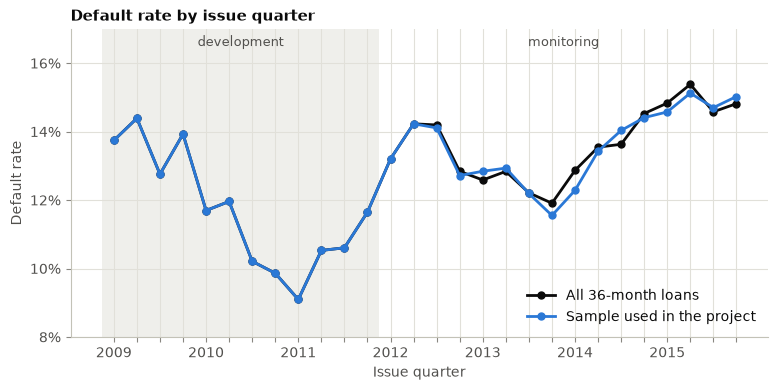

In [14]:
x = range(len(cohorts))
n_development = int(cohorts.index.str[:4].astype(int).isin(DEV_YEARS).sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(-0.5, n_development - 0.5, color="#e1e0d9", alpha=0.5, linewidth=0)
ax.text(n_development / 2 - 0.5, 0.165, "development", ha="center", color=INK_SOFT, fontsize=9)
ax.text((n_development + len(cohorts)) / 2 - 0.5, 0.165, "monitoring", ha="center", color=INK_SOFT, fontsize=9)
ax.plot(x, cohorts["default_rate_full"], color=INK, marker="o", label="All 36-month loans")
ax.plot(x, cohorts["default_rate_sample"], color=MODEL_COLORS["pd_logit"], marker="o", label="Sample used in the project")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0.08, 0.17)
ax.set_xlabel("Issue quarter")
ax.set_ylabel("Default rate")
ax.set_title("Default rate by issue quarter")
label_quarters(ax, list(cohorts.index))
ax.legend(loc="lower right")
fig.savefig(FIGURES / "default_rate_by_quarter.png")